# Time stepping with Irksome

[Irksome](https://www.firedrakeproject.org/Irksome/) (Farrell, Kirby, Marchena-Menéndez,
MacLachlan, Brubeck) generates Runge-Kutta and multistep time discretisations from a
semi-discrete variational form.  One writes the time derivative as `Dt(u)`, chooses a
method, and Irksome builds the coupled stage problem by manipulating the UFL form.

Irksome has exchangeable back ends.  `ngsufl.irksome` is such a back end, so the stage
problems are assembled and solved by NGSolve.  It needs two more packages:

```bash
pip install firedrake-fiat git+https://github.com/firedrakeproject/Irksome
```

## The heat equation

$$ \partial_t u - \Delta u = f \quad \text{in } (0,1)^2, \qquad u = 0 \quad \text{on the boundary} , $$

with the manufactured solution $u_e = e^{-t} (1 + t^2) \sin \pi x \sin \pi y$.

`ngsufl.irksome` has to be imported before the first form is assembled, because
Irksome registers a new UFL type.

In [1]:
import numpy as np
from ngsufl import *
from ngsufl.irksome import BDF, Alexander, BackwardEuler, Dt, GaussLegendre, QinZhang, RadauIIA, TimeStepper

mesh = UnitSquareMesh(8, 8)
V = FunctionSpace(mesh, "CG", 5)
x, y = SpatialCoordinate(mesh)

t = Constant(0.0)
dt = Constant(0.125)

S = sin(pi * x) * sin(pi * y)
u_e = exp(-t) * (1 + t * t) * S
f = (2 * t - (1 + t * t) + 2 * pi**2 * (1 + t * t)) * exp(-t) * S

The semi-discrete problem is written once, with `Dt(u)` for the time derivative.  It
contains the time `t` as a `Constant`; Irksome evaluates the form at the stage times.

In [2]:
u = Function(V, name="u").interpolate(u_e)
v = TestFunction(V)

F = inner(Dt(u), v) * dx + inner(grad(u), grad(v)) * dx - inner(f, v) * dx
bc = DirichletBC(V, 0, "on_boundary")

The two-stage Radau IIA method is L-stable and of order 3.  The stepper solves for both
stages at once, here on a space with twice the unknowns of `V`.

In [3]:
stepper = TimeStepper(F, RadauIIA(2), t, dt, u, bcs=bc)

while float(t) < 0.5 - 1e-12:
    stepper.advance()
    t.assign(float(t) + float(dt))

print(f"t = {float(t):.3f}, L2 error = {errornorm(u_e, u):.3e}")

t = 0.500, L2 error = 3.654e-05


## Convergence in time

The same form with other methods: fully implicit Runge-Kutta methods, diagonally
implicit ones (`stage_type="dirk"`, one stage after the other), and BDF2.  The space
is fine enough for the time error to dominate.

In [4]:
def run(method, nsteps, T=0.5, **kwargs):
    t.assign(0.0)
    dt.assign(T / nsteps)
    u.interpolate(u_e)
    stepper = TimeStepper(F, method, t, dt, u, bcs=bc, **kwargs)
    for _ in range(nsteps):
        stepper.advance()
        t.assign(float(t) + float(dt))
    return errornorm(u_e, u)


methods = [
    ("backward Euler", BackwardEuler(), {}, 1),
    ("Radau IIA, 2 stages", RadauIIA(2), {}, 3),
    ("Gauss-Legendre, 2 stages", GaussLegendre(2), {}, 4),
    ("Qin-Zhang DIRK", QinZhang(), {"stage_type": "dirk"}, 2),
    ("Alexander DIRK", Alexander(), {"stage_type": "dirk"}, 3),
    ("BDF2", BDF(2), {}, 2),
]
steps = (4, 8, 16, 32)

print(f"{'method':26s}" + "".join(f"{'n = %d' % n:>11s}" for n in steps) + "   rates          order")
for name, method, kwargs, order in methods:
    errs = np.array([run(method, n, **kwargs) for n in steps])
    rates = np.log2(errs[:-1] / errs[1:])
    print(f"{name:26s}" + "".join(f"{e:11.2e}" for e in errs) + "   " + " ".join(f"{r:4.2f}" for r in rates) + f"   {order}")

method                          n = 4      n = 8     n = 16     n = 32   rates          order


backward Euler               1.63e-03   7.70e-04   3.72e-04   1.82e-04   1.09 1.05 1.03   1


Radau IIA, 2 stages          3.65e-05   5.27e-06   7.19e-07   9.58e-08   2.79 2.87 2.91   3


Gauss-Legendre, 2 stages     1.61e-05   9.67e-07   6.21e-08   1.74e-08   4.06 3.96 1.83   4


Qin-Zhang DIRK               2.08e-04   5.22e-05   1.31e-05   3.26e-06   2.00 2.00 2.00   2


Alexander DIRK               1.24e-04   2.27e-05   3.72e-06   5.51e-07   2.45 2.61 2.76   3


BDF2                         4.74e-04   1.35e-04   2.52e-05   5.90e-06   1.81 2.42 2.10   2


The observed rates agree with the orders of the methods.  The Alexander method reaches
its third order only slowly, which is the order reduction of diagonally implicit
methods for stiff problems.  For Gauss-Legendre the last value is at the level of the
spatial error, about $2 \cdot 10^{-8}$ on this mesh, which ends the fourth order.

## A nonlinear problem

Nothing changes for a nonlinear form.  Here the diffusion coefficient is $1 + u^2$, and
the stage problem is solved by Newton's method, with the Jacobian from NGSolve.

Newton iterations: 26


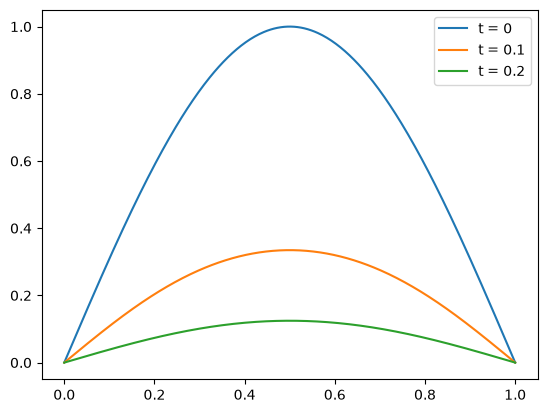

In [5]:
mesh1 = UnitIntervalMesh(40)
V1 = FunctionSpace(mesh1, "CG", 2)
x1, = SpatialCoordinate(mesh1)

t1, dt1 = Constant(0.0), Constant(0.02)
w = Function(V1).interpolate(sin(pi * x1))
z = TestFunction(V1)
F1 = inner(Dt(w), z) * dx + (1 + w**2) * inner(grad(w), grad(z)) * dx

stepper = TimeStepper(F1, RadauIIA(2), t1, dt1, w, bcs=DirichletBC(V1, 0, "on_boundary"))

import matplotlib.pyplot as plt
from ngsufl.pyplot import plot

fig, axes = plt.subplots()
plot(w, axes=axes, label="t = 0")
for k in range(1, 11):
    stepper.advance()
    t1.assign(float(t1) + float(dt1))
    if k % 5 == 0:
        plot(w, axes=axes, label=f"t = {float(t1):.1f}")
axes.legend()
print("Newton iterations:", stepper.num_nonlinear_iterations);

## What is covered

* `TimeStepper(F, method, t, dt, u, bcs=..., solver_parameters=..., nullspace=...)`
  with `stage_type="deriv"` (default), `"value"` or `"dirk"`, and with multistep
  tableaux such as `BDF(2)`.
* Mixed problems.  For time dependent Stokes the pressure null space is given as
  `nullspace=[(1, VectorSpaceBasis(constant=True))]`.
* Time dependent Dirichlet data.

Not available with this back end: the Galerkin-in-time steppers, IMEX methods,
adaptive step size control, bound constraints, and Irksome's stage preconditioners.
Those parts of Irksome use Firedrake directly.  The stage systems are solved with the
solvers of ngsufl, a sparse direct solver by default.